# TSV Concentric · Q3D C/G extraction

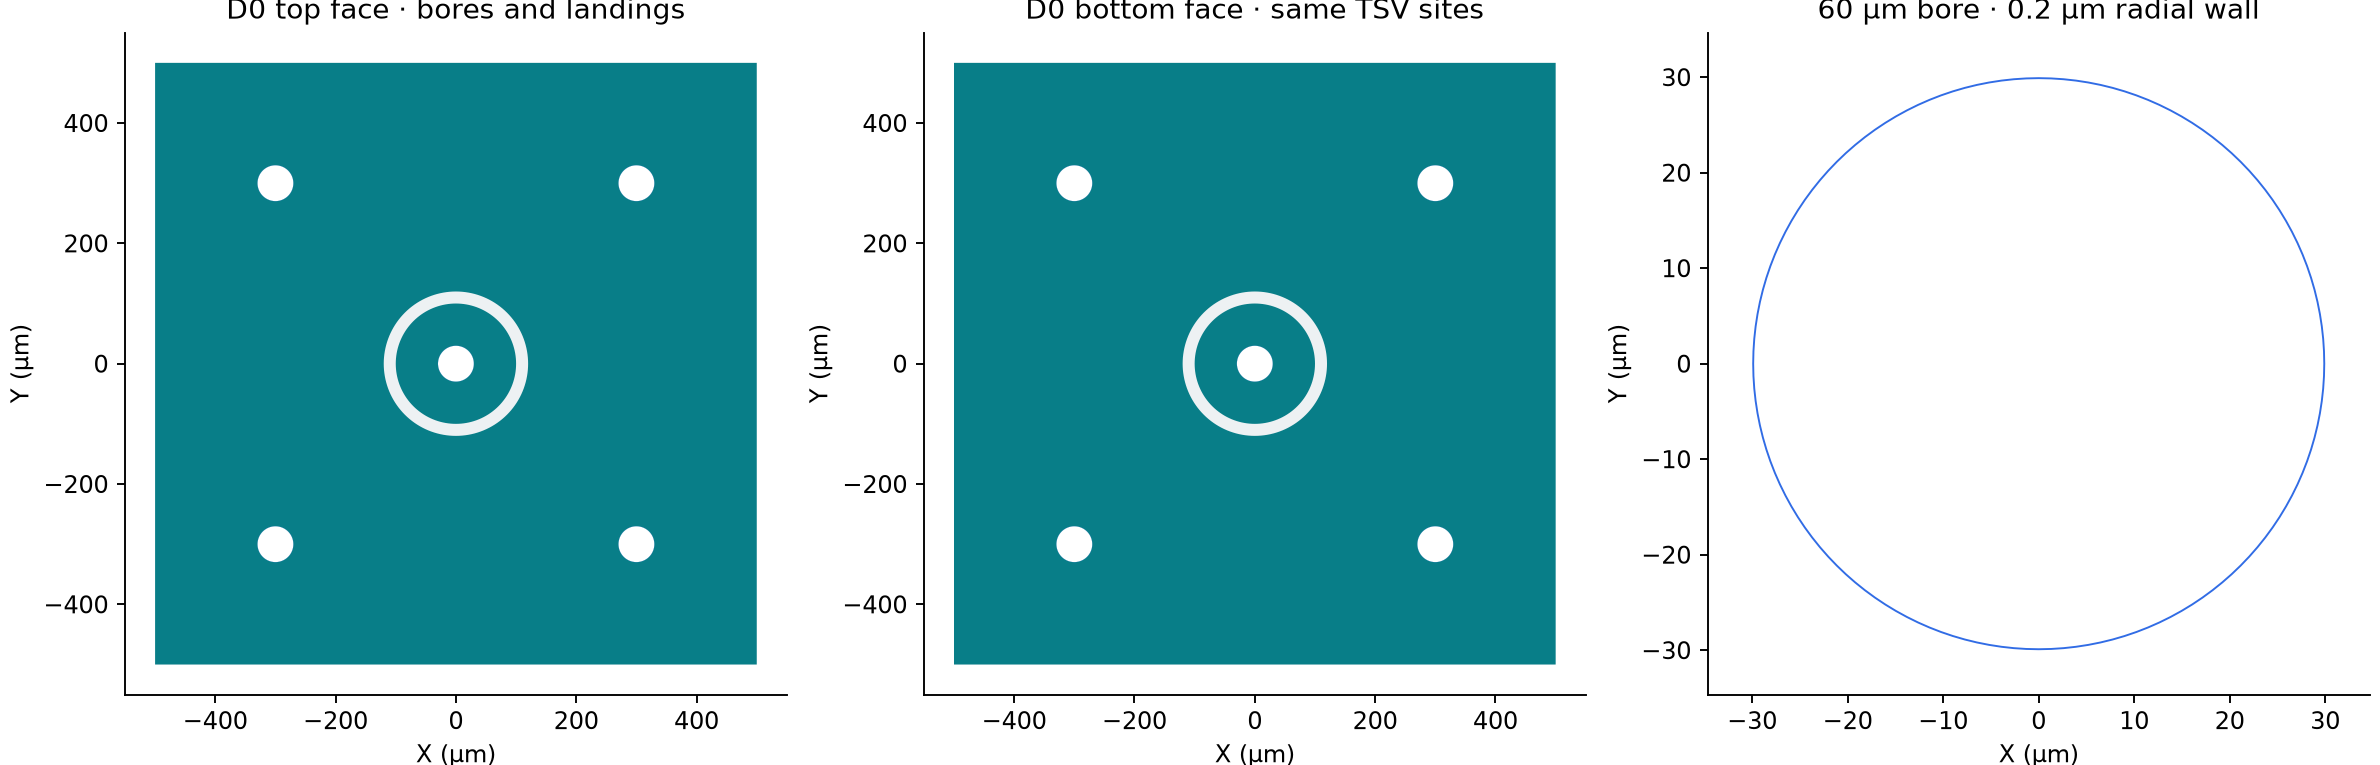

Build a Concentric Signal joined through a hollow TSV, with separate top
and bottom Ground planes connected by four Ground TSVs. The default
full-run flow extracts C/G at 5 GHz with at most three adaptive passes
and 1% convergence. AC R/L is off. These are Human-confirmed first-trial
controls, not accuracy or scientific-success criteria. Native execution
and shared-runtime admission remain pending; this source authoring is
not a solved result. See the [TSV model-inspection
guide](../../../../simulation/tsv-model-inspection.qmd) and [capacitance
requirement](../../../../simulation/requirements/electrostatic-capacitance.qmd).

Fresh construction uses the local shared-physical candidate, not a
published wheel. Retained results keep their original runtime
identities.

Published historical baseline:
[SCGSim](https://github.com/OrPenStrike/scgsim/tree/c9270c7e76e0b2df187dddde462079e00d410dd0).

## Setup and Imports

The following cells use public OrcaPen source and SCGSim models. No
Desktop opens during imports or source authoring.

## Setup and Run Controls

`run` prepares a fresh handoff, invokes the full-solve CLI, then reads
actual results. `prepare_handoff` stops at the portable inputs; `source`
constructs layout/source records only. `analyze_handoff` reads an
explicit returned root without constructing a coupon, calling the
getter, writing GDS, preparing or launching the CLI. Separately,
`build_model` uses `run_control=None` and the candidate’s native
model-only Prepare Only model transaction; `inspect_model` reads that
returned model. Neither model-only action represents Model+Setup or
reuse.

In [ ]:
import hashlib
import json
import subprocess
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path
from uuid import uuid4

from IPython.display import display
from scgsim.aedt import (
    MatrixRunControl,
    PdkMaterial,
    prepare_q3d_from_geometry,
    resolve_prepared_model,
    resolve_results,
)
from scgsim.geometry import (
    ApproximationProfile,
    GeometryBuildInput,
    GeometryPlanSnapshot,
    LayoutPolygonSpec,
    SemanticEntitySpec,
)

import orcapen_sc_pdk
from orcapen_sc_pdk.cells import get_tsv_source_records, tsv_concentric_signal_coupon

# Actions: run | prepare_handoff | analyze_handoff | source | build_model | inspect_model
WORKFLOW_ACTION = "run"
DIE = "D0"
DIE_SIDE_UM = 1000.0
BORE_DIAMETER_UM = 60.0
WALL_THICKNESS_UM = 0.2
SIGNAL_OUTER_RADIUS_UM = 100.0
GAP_UM = 20.0
GROUND_TSV_OFFSET_UM = 300.0
MODEL = "thin_film"  # face films become sheets; TSV levels remain retained_solid.
APPROXIMATION_PROFILE = ApproximationProfile(name=MODEL, revision="v1", parameters={})
SETUP_NAME = "Setup1"
EXTRACTION_FREQUENCY_GHZ = 5.0
MAXIMUM_PASSES = 3
CONVERGENCE_PERCENT = 1.0
MINIMUM_PASSES = 1
MINIMUM_CONVERGED_PASSES = 1
PERCENT_REFINEMENT = 30.0
RUN_CONTROL = (
    None
    if WORKFLOW_ACTION == "build_model"
    else MatrixRunControl(
        setup_name=SETUP_NAME,
        frequency_ghz=EXTRACTION_FREQUENCY_GHZ,
        maximum_passes=MAXIMUM_PASSES,
        convergence_percent=CONVERGENCE_PERCENT,
        minimum_passes=MINIMUM_PASSES,
        minimum_converged_passes=MINIMUM_CONVERGED_PASSES,
        percent_refinement=PERCENT_REFINEMENT,
    )
)
RUN_ID = f"tsv-concentric-q3d-{uuid4().hex[:12]}"
OUTPUT_ROOT = Path(".artifacts/SCGSimExamples/TSV")
RUN_DIR = OUTPUT_ROOT / RUN_ID
SOURCE_DIR = OUTPUT_ROOT / f"{RUN_ID}-source"
RETURNED_RUN_DIR = None  # Set an explicit actual root for analyze_handoff or inspect_model.
PROJECT_NAME = "TSVConcentricQ3DThinFilm"
DESIGN_NAME = "Q3D"
REGION_PADDING_XYZ_UM = (250.0, 250.0, 1000.0)
RESOURCES = None  # No host allocation selected here; native admission is separate.
SIGNAL_ENTITY_IDS = (f"{DIE}/TOP_SIGNAL", f"{DIE}/BOTTOM_SIGNAL", f"{DIE}/SIGNAL_WALL")
GROUND_ENTITY_IDS = (f"{DIE}/TOP_GROUND", f"{DIE}/BACK_GROUND") + tuple(
    f"{DIE}/GROUND_TSV_{i}" for i in range(4)
)
if WORKFLOW_ACTION not in {
    "run",
    "prepare_handoff",
    "analyze_handoff",
    "source",
    "build_model",
    "inspect_model",
}:
    raise ValueError("Unknown WORKFLOW_ACTION")
display({name: version(name) for name in ("orcapen-sc-pdk", "gdsfactory", "scgsim")})

Solver resource flags are not an aggregate OS cap or CAD containment
mechanism. Execute a native action only under the available host
allocation. Q3D has no HFSS port or radiation boundary in this case.
Source/Sink terminals are not added to this terminal-free C/G model.

## Create Simulation Component / Coupon

In [ ]:
if WORKFLOW_ACTION not in {"analyze_handoff", "inspect_model"}:
    orcapen_sc_pdk.activate()
    coupon = tsv_concentric_signal_coupon(
        die=DIE,
        die_side_um=DIE_SIDE_UM,
        bore_diameter_um=BORE_DIAMETER_UM,
        wall_thickness_um=WALL_THICKNESS_UM,
        signal_outer_radius_um=SIGNAL_OUTER_RADIUS_UM,
        gap_um=GAP_UM,
        ground_tsv_offset_um=GROUND_TSV_OFFSET_UM,
    )
    coupon.plot()

M1 Al thickness and the 500 µm Silicon substrate come from the PDK. The
0.2 µm TiN wall is a finite solid; its interior remains empty. These are
nominal OrcaPen research dimensions, not a reproduction of a cited
fabrication process.

## Initialize AEDT Project / App

The selected design is Q3D. The native CLI owns initialization later
during `run` or `build_model`; no manual Desktop attachment or second
client is used here.

## Import GDS and Build the HFSS/Q3D/Q2D Model

The canonical OrcaPen getter supplies actual placed polygon exteriors,
holes, source occurrences, physical levels and materials. This cell only
adopts the explicit case Net grouping and constructs SCGSim’s public
input records. It does not infer connectivity or register invented
children. This cell constructs source input; actual native import/build
belongs to the later CLI transaction, not this source observation.

The background recipe records the existing `px`, `py`, `pz` margins as
the surrounding vacuum complement. Its bounds are already padded; the
recipe does not add those margins to the background a second time.

In [ ]:
if WORKFLOW_ACTION not in {"analyze_handoff", "inspect_model"}:
    bounds = coupon.dbbox()
    regions = coupon.info["tsv_source"]["source_regions"]
    source_bottom = min(r["z_interval_um"][0] for r in regions)
    source_top = max(r["z_interval_um"][1] for r in regions)
    px, py, pz = REGION_PADDING_XYZ_UM
    background = {
        "semantic_id": "CALLER_BACKGROUND",
        "role": "solution_region",
        "material_id": "vacuum",
        "material_kind": "vacuum",
        "priority": 99,
        "geometry_kind": "domain",
        "geometry": {
            "domain_bounds_um": {
                "x_min_um": bounds.left - px,
                "x_max_um": bounds.right + px,
                "y_min_um": bounds.bottom - py,
                "y_max_um": bounds.top + py,
            },
            "z_min_um": source_bottom - pz,
            "z_max_um": source_top + pz,
        },
        "metadata": {
            "meaning": "computational background complement",
            "is_auto_vacuum_region": True,
            "vacuum_region_padding_um": {
                "x_minus_um": px,
                "x_plus_um": px,
                "y_minus_um": py,
                "y_plus_um": py,
                "z_minus_um": pz,
                "z_plus_um": pz,
            },
        },
    }
    source = get_tsv_source_records(coupon, host_solution_region=background)
    caller_nets = {
        **dict.fromkeys(SIGNAL_ENTITY_IDS, "Signal"),
        **dict.fromkeys(GROUND_ENTITY_IDS, "Ground"),
    }
    records = source["geometry_input"]
    stack = source["stack"]
    for layer in stack["layers"]:
        layer["net_id"] = caller_nets[layer["semantic_id"]]
    # Keep physical material records; add only the compiler's kind vocabulary.
    geometry_kinds = {
        "superconductor": "conductor",
        "dielectric": "dielectric",
        "vacuum": "vacuum",
    }
    stack["materials"] = {
        name: {
            **record,
            "kind": geometry_kinds[record["material_kind"]],
            "permittivity": record["relative_permittivity"],
        }
        for name, record in stack["materials"].items()
    }
    build_input = GeometryBuildInput(
        polygons=tuple(LayoutPolygonSpec(**p) for p in records["polygons"]),
        entities=tuple(
            SemanticEntitySpec(**{**e, "net_id": caller_nets.get(e["semantic_id"])})
            for e in records["entities"]
        ),
        solution_regions=records["solution_regions"],
        metadata={**records["metadata"], "caller_final_nets": caller_nets},
    )
    display(
        {
            "source_parameters": coupon.info["tsv_source"]["parameters"],
            "source_contacts": records["metadata"]["source_contacts"],
            "source_ports": records["metadata"]["source_ports"],
            "caller_nets": caller_nets,
            "physical_layer_declarations": {
                e.semantic_id: e.metadata["physical_layer"]
                for e in build_input.entities
                if e.material_kind == "conductor"
            },
        }
    )

## Geometry Verification

These are source observations. Silicon already has the authored bore
holes; the TSV wall is an annulus, not a filled cylinder. In
`thin_film`, face films follow their declared contact side while TSV
`retained_solid` levels stay finite. SCGSim owns the effective-Z mapping
and the actual backend geometry. The current AEDT path consumes sampled
GDS polygon witnesses; exact circular recipes remain source intent, not
active native curve reconstruction.

### Fresh source witness

In [ ]:
if WORKFLOW_ACTION in {"run", "prepare_handoff", "build_model"}:
    SOURCE_DIR.mkdir(parents=True, exist_ok=False)
    gds_path = coupon.write_gds(SOURCE_DIR / "source.gds", with_metadata=False)
    gds_bytes = Path(gds_path).read_bytes()
    gds_sha256 = hashlib.sha256(gds_bytes).hexdigest()
    stack["metadata"]["gds_sha256"] = gds_sha256
    build_input = replace(build_input, metadata={**build_input.metadata, "gds_sha256": gds_sha256})

The exported witness and normalized source records come from the same
component. The backend helper owns actual lowering; this notebook does
not interpret a source GDS hash as an actual native geometry
observation.

## Materials and Boundaries

Al and TiN remain the physical source materials; their PDK
superconducting declarations select ideal native conductor treatment.
Silicon is a perforated dielectric solid. The caller-authored background
is the surrounding complement, not a second overlapping occupied body.
Final Nets are the explicit grouping above, not a connectivity result
inferred by the notebook.

## Simulation Setup

The notebook’s explicit run control selects the Human-confirmed
first-trial physics settings before preparation. `build_model` alone
passes `run_control=None` for the candidate’s model-only transaction,
without an Analysis Setup or sweep. The getter now carries the same
selected neutral `physical_layer` declaration on Entity and stack
records. Shared interpretation belongs to SCGSim, not notebook
arithmetic. Read-only returned-run actions skip every
component/getter/GDS/preparation stage above.

## Simulation Configuration

In [ ]:
HANDOFF = None
if WORKFLOW_ACTION in {"run", "prepare_handoff", "build_model"}:
    # Public detached record, not a claim that GeometryPlan.prepare registered these children.
    snapshot = GeometryPlanSnapshot(
        build_input, json.dumps(stack), gds_bytes, gds_sha256, tuple(source["source_occurrences"])
    )
    used_materials = {e.material_id for e in build_input.entities}
    materials = {
        name: PdkMaterial(
            material_id=name,
            kind=stack["materials"][name]["material_kind"],
            is_superconducting=stack["materials"][name]["is_superconducting"],
            library_name=stack["materials"][name]["aedt_library_name"],
        )
        for name in used_materials
    }
    HANDOFF = prepare_q3d_from_geometry(
        snapshot,
        modeling=APPROXIMATION_PROFILE.name,
        output_dir=RUN_DIR,
        project_name=PROJECT_NAME,
        design_name=DESIGN_NAME,
        materials=materials,
        net_types={"Signal": "Signal", "Ground": "Ground"},
        physical_ground_nets=("Ground",),
        run_control=RUN_CONTROL,
        region_padding_um=(px, px, py, py, pz, pz),
        resources=RESOURCES,
    )
    display(HANDOFF)

The detached snapshot binds the freshly exported GDS to the same source
occurrences and holes. Physical Al/TiN identities are retained; native
ideal superconductor treatment follows the PDK material declaration. The
frozen geometry helper fixes `solve_ac_rl=False`; it exposes no separate
AC R/L option. Only `build_model` omits the Analysis Setup by passing
`run_control=None`.

## Solve and Export

`run` invokes the actual full-solve CLI. `build_model` alone adds the
real `--prepare-only` flag for a model-only build/readback/save/release
transaction. Native failures propagate through `check=True`; no retry or
synthetic result is supplied.

In [ ]:
if WORKFLOW_ACTION in {"run", "build_model"}:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "scgsim.aedt.run",
            "--handoff",
            str(HANDOFF.metadata_path),
            "--execute",
        ]
        + (["--prepare-only"] if WORKFLOW_ACTION == "build_model" else []),
        check=True,
    )

## Adaptive-Pass Convergence / Solver Diagnostics

Read actual returned numerical and performance evidence before
interpreting physics. Three passes is a short first-trial endpoint, not
proof of convergence. Missing/corrupt results and save/release failures
remain strict resolver errors.

In [ ]:
RESULT = None
PREPARED_MODEL = None
if WORKFLOW_ACTION in {"run", "analyze_handoff"}:
    RESULT = resolve_results(HANDOFF.run_dir if WORKFLOW_ACTION == "run" else RETURNED_RUN_DIR)
    RESULT.show_all_results(show_details=True)
elif WORKFLOW_ACTION in {"build_model", "inspect_model"}:
    PREPARED_MODEL = resolve_prepared_model(
        HANDOFF.run_dir if WORKFLOW_ACTION == "build_model" else RETURNED_RUN_DIR
    )

## Results: Plots and Readable Tables

### Physics Analysis Results

The solved C/G tables retain actual net ordering, frequency, units and
result identity. Model-only inspection instead shows sheet/solid
membership, Silicon bores and assignments; it cannot substitute for C/G
or electrical-continuity results. Empty or inconclusive native queries
remain unknown.

In [ ]:
if RESULT is not None:
    display(RESULT.physics_results())
elif PREPARED_MODEL is not None:
    display(PREPARED_MODEL.project_path)
    display(PREPARED_MODEL.readback)

### Simulation Performance / Benchmarks

Display actual solved timing/pass/mesh evidence separately from physics.
The model-only branch retains its preparation/save/release provenance
without a solved benchmark or convergence claim.

In [ ]:
if RESULT is not None:
    display(RESULT.simulation_benchmark())
elif PREPARED_MODEL is not None:
    display({"mode": PREPARED_MODEL.mode, "model_stage": PREPARED_MODEL.model_stage})

## Save and Release AEDT

The public native transaction saves and releases its own Desktop for
either full solving or model-only inspection. Do not open a second
client to release it. Keep `.aedt` and its required companions together;
use a separate writable copy for Human edits, not the hash-bound
returned producer. Old Solid models and images remain historical, not
outputs of this Thin Film source candidate.